# OpenMP k-means

**Naam:** THOMAS TIMMERMANS & MILAN MURONI

**Studentennummer:** _2365790_ & _2262576_



## 0. Gekozen setup

| Parameter | Waarde |
|---|---|
| Dataset | *100000x5.csv* |
| Aantal punten *n* | *100000* |
| Aantal dimensies *d* | *5* |
| *k* (< 100) | *10* |
| repetitions (< 200) | *20* |
| seed | *1337* |
| Aantal herhaalde metingen per configuratie | *5* |
| Thread-aantallen | *1 2 4 8 16 32 64* |
| vsc node | *mindwell batch_graniterapids* |
| Compiler + flags | *gcc 14.3.0 + -O3 -DNDEBUG -std=c++14 -fopenmp* |

## 1. Werkwijze


In [1]:
#pragma omp parallel for schedule(dynamic)
#	for (int r = 0 ; r < repetitions ; r++)
#	{
#		.......
#    }

we paralliliseren de buitense lus (repetitions)
elke repetiotion is volledig appart/onafhankelijk van elkaar
elke repetition kan wel een verschillend aantal stappen hebben waardoor de tijd varieert
daarom hebben we gekozen voor schedule(dynamic) dat zorgt ervoor dat er het moment dat een thread klaar is dat die meteen verder kan (er wordt niet op voorhand alles verdeeld)

_________________________________________________________________________________________________

In [2]:
#pragma omp critical
#    {
#        rng.pickRandomIndices(numRows, indices);
#    }

zo kan elke thread zonder een conflict met anderen threads het object rng gebruiken, anders treedt er datarace op en proberen threads tegelijk het object te gebruiken voor het genereren van de random indices.

_________________________________________________________________________________________________

In [3]:
#pragma omp critical
#		{
#			// Keep track of best clustering
#		if (distanceSquaredSum < bestDistSquaredSum) {
#				bestDistSquaredSum = distanceSquaredSum;
#				bestClusters = clusters;
#			}
#		}

deze maken we ook critical tegen dataraces bij het vergelijken of hij nu beter is, iedereen moet dit nu op een ander tijdstip doen waardoor het weer werkt


_________________________________________________________________________________________________

In [4]:
#for (int p = 0; p < numRows; p++) {	//elk punt uit dataset afgaan
#					std::pair<int, double> newCluster_distance = find_closest_centroid_index_and_distance(p, allData, numCols, centroids);
#					distanceSquaredSum += newCluster_distance.second;
#
#					if (newCluster_distance.first != clusters[p]) {	// als het punt bij een andere centroid hoort dan voorheen
#						clusters[p] = newCluster_distance.first;	// update cluster index
#						changed = true;	// er is een verandering, dus we moeten nog een stap doen
#					}
#			};

Initieel hebben we deze geparalleliseerd, dat gaf minder goede resultaten, het grootste werk ( de aparte repertitions) ging dan nog serieel

Moesten we dit er nu nog bij doen, kregen we naarmate we meer threads lieten werken een langere uitvoer tijd
Dit paralleliseren gaf dus een hoge overheaden deed dus meer slecht dan goed, hoe meer threads we gebruikten hoe slechter dit schaalde.

_________________________________________________________________________________________________

Repetitions = 20
We delen dan in feite 20 onafhankelijke taken uit aan threads in de buitenste loop!
Bij 2, 4, 8, 16 threads verdeelt OpenMP de 20 herhalingen efficient!
Daarna bij 32 of 64 threads zijn er meer threads dan dat er herhalingen zijn waardoor verschillende threads onbenut blijven wat verklaart waarom de uitvoertijd niet versnelt bij 32 en 64 t.o.v. 16 in onze output.

k = 10
met 100 000 punten en 5 dimensies is een enkele stap binnen een repetition best zwaar en moeten er veel berekeningen gebeuren. Deze hebben we echter niet geparalleliseerd omdat als we dit nog eens zouden paralleliseren ga je per repetition uitgevoerd door een aparte thread nog eens sub-threads genereren die daarna allemaal nog eens gejoint moeten worden en dit creeert een enorme overhead en maak het programma trager dan dat we niet paralleliseren!
De parallelisatie van de binenste lus, wat we zien als fine-grained parallelisatie doet dus de winst die we halen uit paralleliseren van de buitenste loop, wat we zien als coarse-grained, dus teniet.

## 2. Vergelijking seriele tijd

Beide metingen uitgevoerd met dezelfde parameters
seed = 1337, 
k = 10, 
repetitions = 20, 
dataset=100000x5.csv

##### Metingen seriele versie 

=== 5 METINGEN in seconden ===

--- Run 1 van 10 ---
3.50793

--- Run 2 van 10 ---
3.52508

--- Run 3 van 10 ---
3.51769

--- Run 4 van 10 ---
3.52263

--- Run 5 van 10 ---
3.49395

gemiddelde seriele tijd: 3.513456 seconden

##### Metingen OpenMP 1-thread

=== 5 METINGEN in seconden ===

--- Run 1 van 5 --- 5.85632

--- Run 2 van 5 --- 5.85198

--- Run 3 van 5 --- 5.85763

--- Run 4 van 5 --- 5.85099

--- Run 5 van 5 --- 5.85256

gemiddelde OpenMP tijd (1 thread) : 5.853896

##### Conclusie

De OpenMP versie met 1 thread is duidelijk wat trager dan de Seriele versie!

Dit komt deels denken we door:
- De OpenMP runtime overhead: het schakelen van #pragma omp parallel for etc brengt vaste runtime kosten met zich mee

- Compiler optimalisaties: de compiler optimaliseert waarschijnlijk bij de seriele versie zelf de seriele lussen en bij de multi threading versie gebeurt dit niet


### 3. Efficientie en speedup

#### Gemiddelden speedup en efficientie

gemiddelde ($\bar{T}$), de standaardafwijking ($\sigma$), de speedup ($S = \frac{T_s}{T_p}$) en de efficiëntie ($E = \frac{S}{p}$)

(AI laten berekenen op basis van onze waardes)

1 thread: gemiddelde $\bar{T} = 5{,}8539\text{ s}$, standaardafwijking $\sigma = 0{,}0028$, Efficientie = 100%  

2 threads: $\bar{T} = 3{,}1187\text{ s}$, ($\sigma = 0{,}0021$), $\text{Speedup} = \mathbf{1{,}88}$, Efficientie = 93,8%

4 threads: $\bar{T} = 1{,}7079\text{ s}$ ($\sigma = 0{,}0017$), $\text{Speedup} = \mathbf{3{,}43}$, Efficientie = 85,7%

8 threads: $\bar{T} = 1{,}2876\text{ s}$ ($\sigma = 0{,}0021$), $\text{Speedup} = \mathbf{4{,}55}$, Efficientie = 56,8%

16 threads: $\bar{T} = 1{,}1925\text{ s}$ ($\sigma = 0{,}0043$), $\text{Speedup} = \mathbf{4{,}91}$, Efficientie = 30,7%

32 threads: $\bar{T} = 1{,}2075\text{ s}$ ($\sigma = 0{,}0087$), $\text{Speedup} = \mathbf{4{,}85}$, Efficientie = 15,2%

64 threads: $\bar{T} = 1{,}2548\text{ s}$ ($\sigma = 0{,}0681$), $\text{Speedup} = \mathbf{4{,}67}$, Efficientie = 7,3%

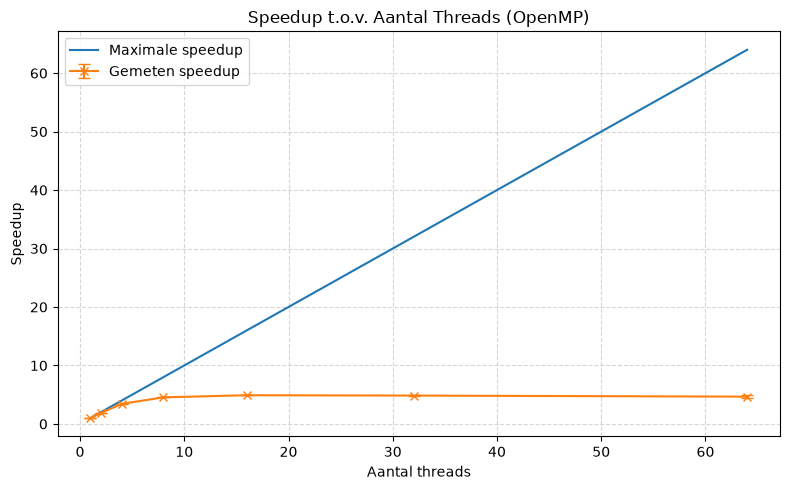

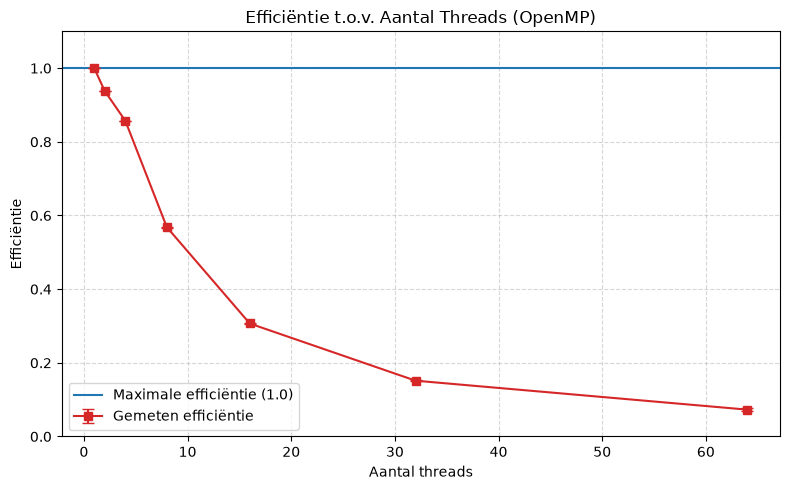

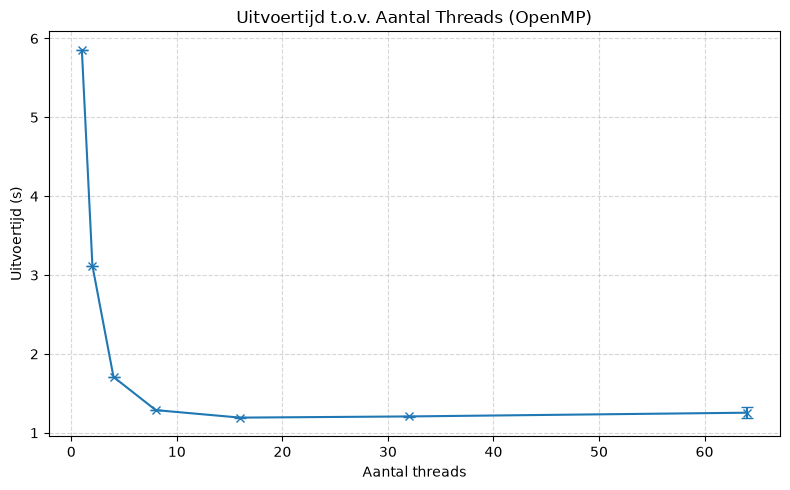

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Data uit Slurm output
threads = np.array([1, 2, 4, 8, 16, 32, 64])
mean_times = np.array([5.853896, 3.118758, 1.707934, 1.287568, 1.192536, 1.207524, 1.254780])
std_times = np.array([0.0028, 0.0021, 0.0017, 0.0021, 0.0043, 0.0087, 0.0681])

# Referentietijd (1 thread OpenMP)
T1 = mean_times[0]
std_Ts = std_times[0]

# Berekening van Speedup en Efficiëntie (schaal 0.0 tot 1.0)
speedup = T1 / mean_times
efficiency = speedup / threads

# Foutenvoortplanting direct op Efficiëntie
std_efficiency = efficiency * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Foutenvoortplanting op Speedup
std_speedup = speedup * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Figuur 1: Speedup 
plt.figure(figsize=(8, 5))
plt.plot(threads, threads, color='tab:blue', label='Maximale speedup')
plt.errorbar(threads, speedup, yerr=std_speedup, fmt='x-', color='tab:orange', 
             capsize=4, label='Gemeten speedup')

plt.xlabel('Aantal threads')
plt.ylabel('Speedup')
plt.title('Speedup t.o.v. Aantal Threads (OpenMP)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 2: Efficiëntie 
plt.figure(figsize=(8, 5))
plt.axhline(y=1.0, color='tab:blue', linestyle='-', label='Maximale efficiëntie (1.0)')
plt.errorbar(threads, efficiency, yerr=std_efficiency, fmt='s-', color='tab:red', 
             capsize=4, label='Gemeten efficiëntie')

plt.xlabel('Aantal threads')
plt.ylabel('Efficiëntie')
plt.title('Efficiëntie t.o.v. Aantal Threads (OpenMP)')
plt.ylim(0.0, 1.1)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 3: Uitvoertijd in functie van het aantal threads (zoals voorbeeld)
plt.figure(figsize=(8, 5))
plt.errorbar(threads, mean_times, yerr=std_times, fmt='x-', color='tab:blue', 
             capsize=4, label='Gemeten uitvoertijd')

plt.xlabel('Aantal threads')
plt.ylabel('Uitvoertijd (s)')
plt.title('Uitvoertijd t.o.v. Aantal Threads (OpenMP)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Besluit

* **Speedup & Efficiëntie:** Tot 4 threads schaalt het algoritme uitstekend met een vrijwel lineaire speedup ($3{,}43\times$) en een hoge efficiëntie van $85{,}7\%$.
* **Foutbalken:** De foutbalken (standaardafwijkingen) op beide grafieken zijn nauwelijks zichtbaar. Dit laat zien dat er zeer hoge reproduceerbaarheid en stabiele uitvoertijden op het VSC-cluster zijn uitgevoerd.


##### Schaalbaarheid van de Implementatie
1. **Goede initiële schaalbaarheid (1 - 4 threads):** De 20 herhalingen worden efficiënt verdeeld over de threads met minimale overhead.

2. **Afnemende meeropbrengst (8 - 16 threads):** De speedup vlakt af en bereikt zijn maximum van **$4{,}91\times$** bij 16 threads (efficiëntie daalt naar $30{,}7\%$). Dit komt door de seriële bottleneck en load imbalance (20 herhalingen verdelen over 16 threads).

3. **Verlies van schaalbaarheid (32 - 64 threads):** Bij 32 en 64 threads daalt de snelheid en stort de efficiëntie in ($7{,}3\%$). Met slechts 20 herhalingen blijven 12 tot 44 threads volledig **unemployed (idle)**, wat zorgt voor onnodige OpenMP-beheersoverhead en thread-contentie.

### 4. Seriele fractie inschatten (8 threads)

T1 = 5,853896s (gemiddelde tijd voor 1 thread),
T8 = 1,287568s (gemiddelde tijd 8 threads)

Wet van Amdahl: Theoretische speedup Sp bij p threads:
$$S_p = \frac{1}{s + \frac{1 - s}{p}}$$

$S_8 = \frac{5{,}853896}{1{,}287568} \approx \mathbf{4{,}546476}$ (speedup bij 8 threads),
p = 8 (8 threads)

formule omzetten naar s : $$s = \frac{\frac{1}{S_p} - \frac{1}{p}}{1 - \frac{1}{p}}$$

waardes invullen: $$s = \frac{\frac{1}{4{,}546476} - \frac{1}{8}}{1 - \frac{1}{8}} = \frac{0{,}219950 - 0{,}125}{0{,}875} = \frac{0{,}094950}{0{,}875} \approx \mathbf{0{,}108514}$$

#### Conclusie
De geschatte seriële fractie $s$ bedraagt **10,85%**. Dit betekent dat circa 89,15% van de uitvoeringstijd effectief parallel geschaald wordt. De overige 10,85% wordt veroorzaakt door het seriële deel van de code, synchronisatie-overhead (`#pragma omp critical`), beheerskosten van de OpenMP-threads en load imbalance.

### 5. Geschatte uitvoerdtijd (16 threads)

s = 0,108514, p = 16

$$S_{16, \text{pred}} = \frac{1}{s + \frac{1 - s}{16}} = \frac{1}{0{,}108514 + \frac{1 - 0{,}108514}{16}} = \frac{1}{0{,}108514 + 0{,}055718} = \frac{1}{0{,}164232} \approx \mathbf{6{,}0889}$$

$$T_{16, \text{pred}} = \frac{T_1}{S_{16, \text{pred}}} = \frac{5{,}853896}{6{,}0889} \approx \mathbf{0{,}9614\text{ s}}$$

Voorspelde tijd: 0,9614s
Gemeten tijd: 1,1925s

==> verschil 1,1925-0,9614 = 0,2311

In werkelijkheid is het programma dus trager dan dat Amdahl voorspelt!

## 6. Verwachtingen bij Opschalen van Cores & Limiet bij Oneindig Veel Cores

### 1. Verwachtingen bij Stijgend Aantal Cores ($p \rightarrow \infty$)
Naarmate we steeds meer CPU-cores toevoegen, zien we twee mogelijkheden:

* **Fase 1 (Afnemende meeropbrengst):** De parallelle uitvoertijd daalt aanvankelijk, maar steeds trager. Volgens Amdahl's Law kan immers enkel het parallelle gedeelte ($1 - s \approx 89{,}15\%$) versneld worden.
* **Fase 2 (Verlies van snelheid / Verzadiging):** Zodra het aantal threads groter wordt dan het aantal herhalingen ($20$ herhalingen), blijven extra threads volledig **onbenut (idle)**. Bovendien neemt de OpenMP-overhead (thread-creatie, synchronisatie bij `#pragma omp critical` en geheugen-contentie) toe, waardoor de totale tijd zelfs licht gaat **stijgen** (zoals te zien is bij 32 en 64 threads).

### 2. Limiet bij oneindig veel cores

Volgens Amdahl is de maximale speedup bij een oneindig aantal cores begrensd door seriele fractie
$$S_{\infty} = \lim_{p \to \infty} \frac{1}{s + \frac{1 - s}{p}} = \frac{1}{s}$$

Met onze geschatte seriele fractie $s = 0{,}108514$:

$$S_{\infty} = \frac{1}{0{,}108514} \approx \mathbf{9{,}215}$$

De theoretisch minimale uitvoertijd ($T_{\infty}$) wordt dan:

$$T_{\infty} = \frac{T_1}{S_{\infty}} = s \cdot T_1 = 0{,}108514 \times 5{,}853896\text{ s} \approx \mathbf{0{,}6352\text{ seconden}}$$

#### 3. Praktische limiet van de huidige implementatie
In onze specifieke implementatie is de maximale parallellisatie echter begrensd door het aantal herhalingen ($\text{repetitions} = 20$). Met $p \ge 20$ kan elke herhaling hoogstens op 1 eigen thread draaien. 

De minimale tijd voor 1 herhaling bepaalt in de praktijk de ondergrens van de uitvoertijd (ongeveer $T_1 / 20 \approx 0{,}29\text{ s}$ per herhaling, plus de seriële synchronisatie-overhead). Extra cores boven de 20 kunnen de uitvoering van een individuele herhaling niet meer versnellen.


## 7. Op welke manieren schaalbaarheid verbeteren

Om de schaalbaarheid voorbij 16 en 20 threads te verbeteren, moeten we de seriële fractie $s$ verkleinen en fijnerkorrelige (*fine-grained*) parallelisatie toepassen.

### 1. Verwijderen/Optimaliseren van Kritieke Secties (`#pragma omp critical`)
* **Idee:** Momenteel worden het genereren van random indices en het opslaan van het beste resultaat beveiligd met een `#pragma omp critical`. Dit dwingt alle threads om op elkaar te wachten (seriële bottleneck).
* **Werking:** 
  * Gebruik een thread-safe Random Number Generator in plaats van één gedeeld `rng`-object.
  * Laat elke thread zijn eigen `bestClusters` lokaal bijhouden en voer pas helemaal aan het einde van de parallelle regio één reductie of snelle vergelijking uit.
* **Vereiste werkhoeveelheid:** **Laag (1 uurtje werk).** Dit vermindert de seriële fractie $s$ direct aanzienlijk.

---

### 2. Parallelisatie binnen de K-means Iteratieloop met Reductie (Fine-grained benadering)
* **Idee:** Als de parameters zo gekozen worden dat `repetitions` klein is maar $n$ (aantal datapunten) groot, paralleliseer dan uitsluitend de iteraties binnen k-means over de $n$ datapunten.
* **Werking:** Verdeel de 100.000 punten over de beschikbare threads om afstanden te berekenen.
* **Vereiste werkhoeveelheid:** **Middelmatig werk (2 uurtjes)** 